# Laboratorium 3 – Sieć neuronowa Hopfielda

In [2]:
%pip install numpy pandas matplotlib scikit-learn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------------ --------------------------- 3.9/12.6 MB 21.3 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 29.6 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 24.6 MB/s  0:00:00
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ------------- -------------------------- 3.7/10.7 MB 18.1 MB/s eta 0:00:01
   ------------------------------- -------- 8.4/10.7 MB 20.0 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 18.6 MB/s  0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Przygotowanie zbioru danych – wzorce cyfr

### 1.1. Wzorcowe obrazy cyfr

Każda cyfra jest reprezentowana przez obraz 8 × 8 pikseli.
Kodowanie bipolarne:
- 1 – piksel aktywny (ciemny),
- -1 – piksel nieaktywny (jasny).

In [27]:
patterns = np.array([
    # 0
    [
        [-1, 1, 1, 1, 1, 1, 1, -1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [-1, 1, 1, 1, 1, 1, 1, -1]
    ],
    # 1
    [
        [-1, -1, -1, 1, 1, -1, -1, -1],
        [-1, -1, 1, 1, 1, -1, -1, -1],
        [-1, 1, -1, 1, 1, -1, -1, -1],
        [-1, -1, -1, 1, 1, -1, -1, -1],
        [-1, -1, -1, 1, 1, -1, -1, -1],
        [-1, -1, -1, 1, 1, -1, -1, -1],
        [-1, -1, -1, 1, 1, -1, -1, -1],
        [1, 1, 1, 1, 1, 1, 1, 1]
    ],
    # 2
    [
        [-1, 1, 1, 1, 1, 1, 1, -1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, -1, -1, 1, 1, -1],
        [-1, -1, -1, -1, 1, 1, -1, -1],
        [-1, -1, -1, 1, 1, -1, -1, -1],
        [-1, -1, 1, 1, -1, -1, -1, -1],
        [1, 1, 1, 1, 1, 1, 1, 1]
    ],
    # 3
    [
        [1, 1, 1, 1, 1, 1, 1, -1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, 1, 1, 1, 1, -1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, -1]
    ],
    # 4
    [
        [1, 1, -1, -1, -1, 1, 1, -1],
        [1, 1, -1, -1, -1, 1, 1, -1],
        [1, 1, -1, -1, -1, 1, 1, -1],
        [1, 1, -1, -1, -1, 1, 1, -1],
        [1, 1, 1, 1, 1, 1, 1, 1],
        [-1, -1, -1, -1, -1, 1, 1, -1],
        [-1, -1, -1, -1, -1, 1, 1, -1],
        [-1, -1, -1, -1, -1, 1, 1, -1]
    ],
    # 5
    [
        [1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, -1, -1, -1, -1, -1, -1],
        [1, 1, -1, -1, -1, -1, -1, -1],
        [1, 1, 1, 1, 1, 1, 1, -1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [-1, 1, 1, 1, 1, 1, 1, -1]
    ],
    # 6
    [
        [-1, -1, 1, 1, 1, 1, 1, 1],
        [-1, 1, 1, -1, -1, -1, -1, -1],
        [1, 1, -1, -1, -1, -1, -1, -1],
        [1, 1, 1, 1, 1, 1, 1, -1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [-1, 1, 1, -1, -1, -1, 1, 1],
        [-1, -1, 1, 1, 1, 1, 1, -1]
    ],
    # 7
    [
        [1, 1, 1, 1, 1, 1, 1, 1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, -1, -1, 1, 1, -1],
        [-1, -1, -1, -1, 1, 1, -1, -1],
        [-1, -1, -1, 1, 1, -1, -1, -1],
        [-1, -1, 1, 1, -1, -1, -1, -1],
        [-1, 1, 1, -1, -1, -1, -1, -1],
        [1, 1, -1, -1, -1, -1, -1, -1]
    ],
    # 8
    [
        [-1, 1, 1, 1, 1, 1, 1, -1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [-1, 1, 1, -1, -1, 1, 1, -1],
        [-1, -1, 1, 1, 1, 1, -1, -1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [-1, 1, 1, 1, 1, 1, 1, -1]
    ],
    # 9
    [
        [-1, 1, 1, 1, 1, 1, 1, -1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [1, 1, -1, -1, -1, -1, 1, 1],
        [-1, 1, 1, 1, 1, 1, 1, 1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, -1, -1, -1, -1, -1, 1, 1],
        [-1, 1, 1, 1, 1, 1, 1, -1]
    ]
])

### 1.2. Kontrola wymiarów i kodowania wzorców

Sprawdzamy liczbę obrazów, ich wymiary oraz dopuszczalne wartości pikseli.

In [28]:
print("Liczba wzorców:", patterns.shape[0])
print("Wymiary obrazu:", patterns.shape[1:])
print("Liczba pikseli:", patterns.shape[1] * patterns.shape[2])
print("Wartości pikseli:", np.unique(patterns))

Liczba wzorców: 10
Wymiary obrazu: (8, 8)
Liczba pikseli: 64
Wartości pikseli: [-1  1]


### 1.3. Wizualizacja wzorcowych obrazów cyfr

Wyświetlenie wszystkich dziesięciu wzorców w postaci obrazów 8 × 8 pikseli.

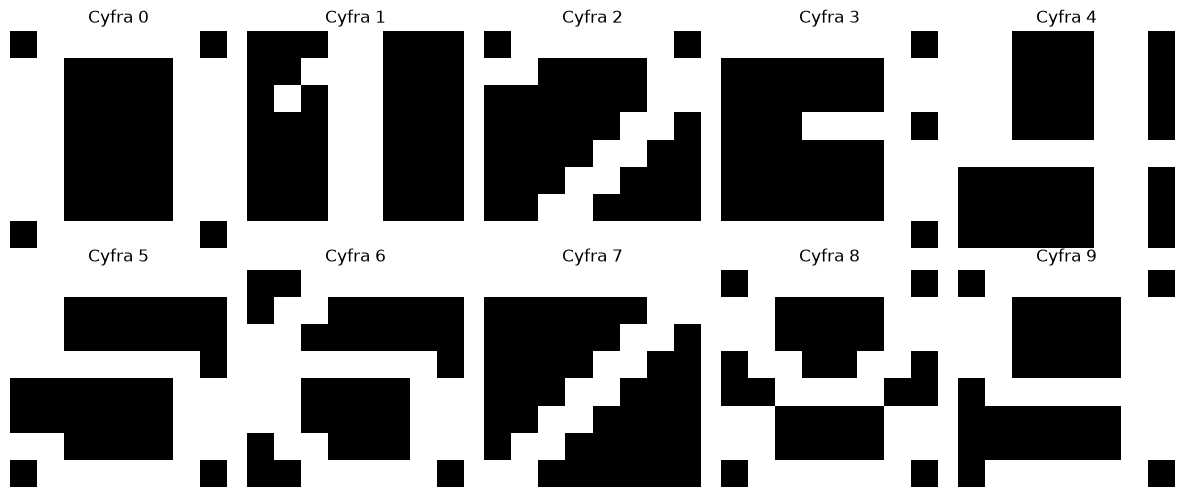

In [29]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(patterns[i], cmap="gray")
    ax.set_title(f"Cyfra {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()